**Etapa 02: Preparação, Limpeza e Análise Exploratória**

**Tratamento e Limpeza Inicial**

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

**Carregamento do dataset**

In [5]:
df = pd.read_csv('pokemon_complete_stats.csv')  # ajuste o caminho conforme o ambiente (ex: '/content/...' no Google Colab)

In [6]:
print("Primeiras 5 linhas do DataFrame:")
display(df.head())

Primeiras 5 linhas do DataFrame:


,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense,special_attack,special_defense,speed,abilities,generation,is_legendary,is_mythical,color,shape,capture_rate
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49,65,65,45,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63,80,80,60,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83,100,100,80,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
3,4,charmander,6,85,62.0,fire,NaN,39,52,43,60,50,65,"blaze, solar-power",generation-i,False,False,red,upright,45
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58,80,65,80,"blaze, solar-power",generation-i,False,False,red,upright,45


In [7]:
print("Informações gerais do DataFrame:")
df.info()

Informações gerais do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
 10  special_attack   1351 non-null   int64  
 11  special_defense  1351 non-null   int64  
 12  speed            1351 non-null   int64  
 13  abilities        1337 non-null   object 
 14  generation       1351 non-null   object 
 15  is_legendary     1351 non-null   bool   
 16  is_mythical      1351 non-n

In [8]:
print("\nValores ausentes por coluna:")
display(df.isnull().sum())


Valores ausentes por coluna:


,0
id,0
name,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


In [9]:
print("\nNúmero de linhas duplicadas:")
display(df.duplicated().sum())
if df.duplicated().sum() > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicatas removidas. Novo número de linhas:", len(df))
else:
    print("Nenhuma duplicata encontrada.")


Número de linhas duplicadas:


np.int64(0)

Nenhuma duplicata encontrada.


**Tratamento de Valores Ausentes**

A identificação acima mostrou valores ausentes em três colunas. O tratamento aplicado a cada uma considera o significado da coluna:

- `type_2`: a ausência significa que o Pokémon possui apenas um tipo elementar (não tem tipo secundário). Preenchemos com a categoria `'none'` em vez de descartar os registros.
- `abilities`: apenas 14 registros ausentes (~1% do total). Preenche com o rótulo `'não informado'` para manter os registros no dataset.
- `base_experience`: é uma variável numérica contínua; preenchemos os 49 valores ausentes (~3,6%) com a **mediana** da coluna, por ser mais robusta a outliers do que a média.

In [10]:
df['type_2'] = df['type_2'].fillna('none')
df['abilities'] = df['abilities'].fillna('não informado')

mediana_base_experience = df['base_experience'].median()
df['base_experience'] = df['base_experience'].fillna(mediana_base_experience)

print(f"Mediana usada para preencher 'base_experience': {mediana_base_experience}")
print("\nValores ausentes por coluna após o tratamento:")
display(df.isnull().sum())

Mediana usada para preencher 'base_experience': 165.0

Valores ausentes por coluna após o tratamento:


,0
id,0
name,0
height_dm,0
weight_hg,0
base_experience,0
type_1,0
type_2,0
hp,0
attack,0
defense,0


**Checagem de Inconsistências de Tipos de Dados**

Verificar se os tipos computacionais batem com o esperado (conforme o dicionário de dados da Etapa 01), se não há valores negativos nas colunas de estatísticas de combate (fisicamente impossíveis) e se as colunas categóricas não têm inconsistências de grafia (espaços extras ou variação de maiúsculas/minúsculas).

In [11]:
tipos_esperados = {
    'id': 'int64', 'height_dm': 'int64', 'weight_hg': 'int64', 'base_experience': 'float64',
    'hp': 'int64', 'attack': 'int64', 'defense': 'int64', 'special_attack': 'int64',
    'special_defense': 'int64', 'speed': 'int64', 'capture_rate': 'int64',
    'is_legendary': 'bool', 'is_mythical': 'bool',
}

print("Checagem de tipos computacionais:")
for col, tipo_esperado in tipos_esperados.items():
    tipo_real = str(df[col].dtype)
    status = 'OK' if tipo_real == tipo_esperado else 'DIVERGENTE'
    print(f"  {col:<20} esperado={tipo_esperado:<10} real={tipo_real:<10} [{status}]")

colunas_numericas_positivas = ['height_dm', 'weight_hg', 'base_experience', 'hp', 'attack',
                                'defense', 'special_attack', 'special_defense', 'speed', 'capture_rate']
print("\nChecagem de valores negativos (não deveriam existir):")
for col in colunas_numericas_positivas:
    n_negativos = (df[col] < 0).sum()
    print(f"  {col:<20} valores negativos: {n_negativos}")

print("\nChecagem de inconsistências de grafia em colunas categóricas:")
for col in ['type_1', 'type_2', 'color', 'shape', 'generation']:
    valores = sorted(df[col].dropna().unique())
    com_espacos = [v for v in valores if v != v.strip()]
    print(f"  {col:<12} valores únicos: {len(valores):<3} | com espaços extras: {len(com_espacos)}")

Checagem de tipos computacionais:
  id                   esperado=int64      real=int64      [OK]
  height_dm            esperado=int64      real=int64      [OK]
  weight_hg            esperado=int64      real=int64      [OK]
  base_experience      esperado=float64    real=float64    [OK]
  hp                   esperado=int64      real=int64      [OK]
  attack               esperado=int64      real=int64      [OK]
  defense              esperado=int64      real=int64      [OK]
  special_attack       esperado=int64      real=int64      [OK]
  special_defense      esperado=int64      real=int64      [OK]
  speed                esperado=int64      real=int64      [OK]
  capture_rate         esperado=int64      real=int64      [OK]
  is_legendary         esperado=bool       real=bool       [OK]
  is_mythical          esperado=bool       real=bool       [OK]

Checagem de valores negativos (não deveriam existir):
  height_dm            valores negativos: 0
  weight_hg            valores nega

**Resumo Estatístico Discreto**



In [12]:
numerical_summary = df.describe()
print("Médias das Variáveis Numéricas:")
display(numerical_summary.loc[['mean']])

Médias das Variáveis Numéricas:


,id,height_dm,weight_hg,base_experience,hp,attack,defense,special_attack,special_defense,speed,capture_rate
mean,2841.69208,20.443375,991.059956,162.054774,71.673575,82.757957,76.19393,75.418209,74.11547,72.0,89.110289


In [13]:
print("\nMedianas das Variáveis Numéricas (50º Percentil):")
display(numerical_summary.loc[['50%']])


Medianas das Variáveis Numéricas (50º Percentil):


,id,height_dm,weight_hg,base_experience,hp,attack,defense,special_attack,special_defense,speed,capture_rate
50%,676.0,11.0,326.0,165.0,70.0,80.0,70.0,69.0,70.0,70.0,55.0


In [14]:
print("\nQuartis das Variáveis Numéricas (25º e 75º Percentis):")
display(numerical_summary.loc[['25%', '75%']])


Quartis das Variáveis Numéricas (25º e 75º Percentis):


,id,height_dm,weight_hg,base_experience,hp,attack,defense,special_attack,special_defense,speed,capture_rate
25%,338.5,6.0,94.5,74.0,55.0,60.0,55.0,50.0,54.0,49.0,45.0
75%,1013.5,17.0,853.5,217.5,85.0,102.5,95.0,97.0,90.0,95.0,120.0


In [15]:
print("\nAmplitude (Máx - Mín) das Variáveis Numéricas:")
display(numerical_summary.loc['max'] - numerical_summary.loc['min'])


Amplitude (Máx - Mín) das Variáveis Numéricas:


,0
id,10325.0
height_dm,999.0
weight_hg,10000.0
base_experience,572.0
hp,254.0
attack,185.0
defense,245.0
special_attack,206.0
special_defense,230.0
speed,195.0


In [16]:
print("Resumo estatístico das colunas numéricas:")
display(df.describe())

Resumo estatístico das colunas numéricas:


,id,height_dm,weight_hg,base_experience,hp,attack,defense,special_attack,special_defense,speed,capture_rate
count,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000
mean,2841.692080,20.443375,991.059956,162.054774,71.673575,82.757957,76.193930,75.418209,74.115470,72.000000,89.110289
std,4139.019112,53.238467,1953.115812,81.022914,26.827529,32.351906,30.712902,34.026272,27.800826,30.642043,74.392734
min,1.000000,1.000000,0.000000,36.000000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,3.000000
25%,338.500000,6.000000,94.500000,74.000000,55.000000,60.000000,55.000000,50.000000,54.000000,49.000000,45.000000
50%,676.000000,11.000000,326.000000,165.000000,70.000000,80.000000,70.000000,69.000000,70.000000,70.000000,55.000000
75%,1013.500000,17.000000,853.500000,217.500000,85.000000,102.500000,95.000000,97.000000,90.000000,95.000000,120.000000
max,10326.000000,1000.000000,10000.000000,608.000000,255.000000,190.000000,250.000000,216.000000,250.000000,200.000000,255.000000


In [17]:
print("\nResumo estatístico das colunas categóricas:")
display(df.describe(include=['object']))


Resumo estatístico das colunas categóricas:


,name,type_1,type_2,abilities,generation,color,shape
count,1351,1351,1351,1351,1351,1351,1351
unique,1351,18,19,720,9,10,14
top,meowstic-female-mega,water,none,levitate,generation-i,blue,upright
freq,1,160,586,38,238,216,284


In [18]:
print("\nFrequência de 'type_1':")
display(df['type_1'].value_counts())


Frequência de 'type_1':


,count
type_1,
water,160
normal,139
grass,122
electric,100
bug,95
psychic,86
fire,84
rock,83
dark,63


In [19]:
print("\nFrequência de 'generation':")
display(df['generation'].value_counts())


Frequência de 'generation':


,count
generation,
generation-i,238
generation-v,185
generation-iii,167
generation-ix,149
generation-viii,133
generation-vii,131
generation-iv,129
generation-ii,115
generation-vi,104


**Identificação de Outliers — Formas Especiais**

Antes de plotar as distribuições, vale investigar valores extremos em `id`, `height_dm` e `weight_hg`. O dataset inclui formas alternativas de Pokémon (Gigantamax, Mega Evolução, formas regionais etc.), todas com `id > 9000`, que têm estatísticas de altura/peso muito fora do padrão das espécies-base e distorcem os gráficos se não forem identificadas.

In [20]:
formas_especiais = df[df['id'] > 9000]
print(f"Registros com id > 9000 (formas especiais): {len(formas_especiais)} de {len(df)} "
      f"({len(formas_especiais) / len(df):.1%})")

print("\nExemplos de outliers extremos causados por essas formas:")
display(df.nlargest(3, 'height_dm')[['id', 'name', 'height_dm']])
display(df.nlargest(3, 'weight_hg')[['id', 'name', 'weight_hg']])

# Sinaliza as formas especiais para uso nos gráficos a seguir
df['is_special_form'] = df['id'] > 9000

Registros com id > 9000 (formas especiais): 326 de 1351 (24.1%)

Exemplos de outliers extremos causados por essas formas:


,id,name,height_dm
1214,10190,eternatus-eternamax,1000
1244,10220,centiskorch-gmax,750
1249,10225,duraludon-gmax,430


,id,name,weight_hg
1219,10195,venusaur-gmax,10000
1220,10196,charizard-gmax,10000
1221,10197,blastoise-gmax,10000


**Visualização de Dados**

In [21]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
if 'id' in numerical_cols:
    numerical_cols.remove('id')  # 'id' é um identificador, não uma variável de distribuição

In [22]:
num_plots = len(numerical_cols)

In [23]:
num_cols_subplot = 3

In [24]:
num_rows_subplot = (num_plots + num_cols_subplot - 1) // num_cols_subplot

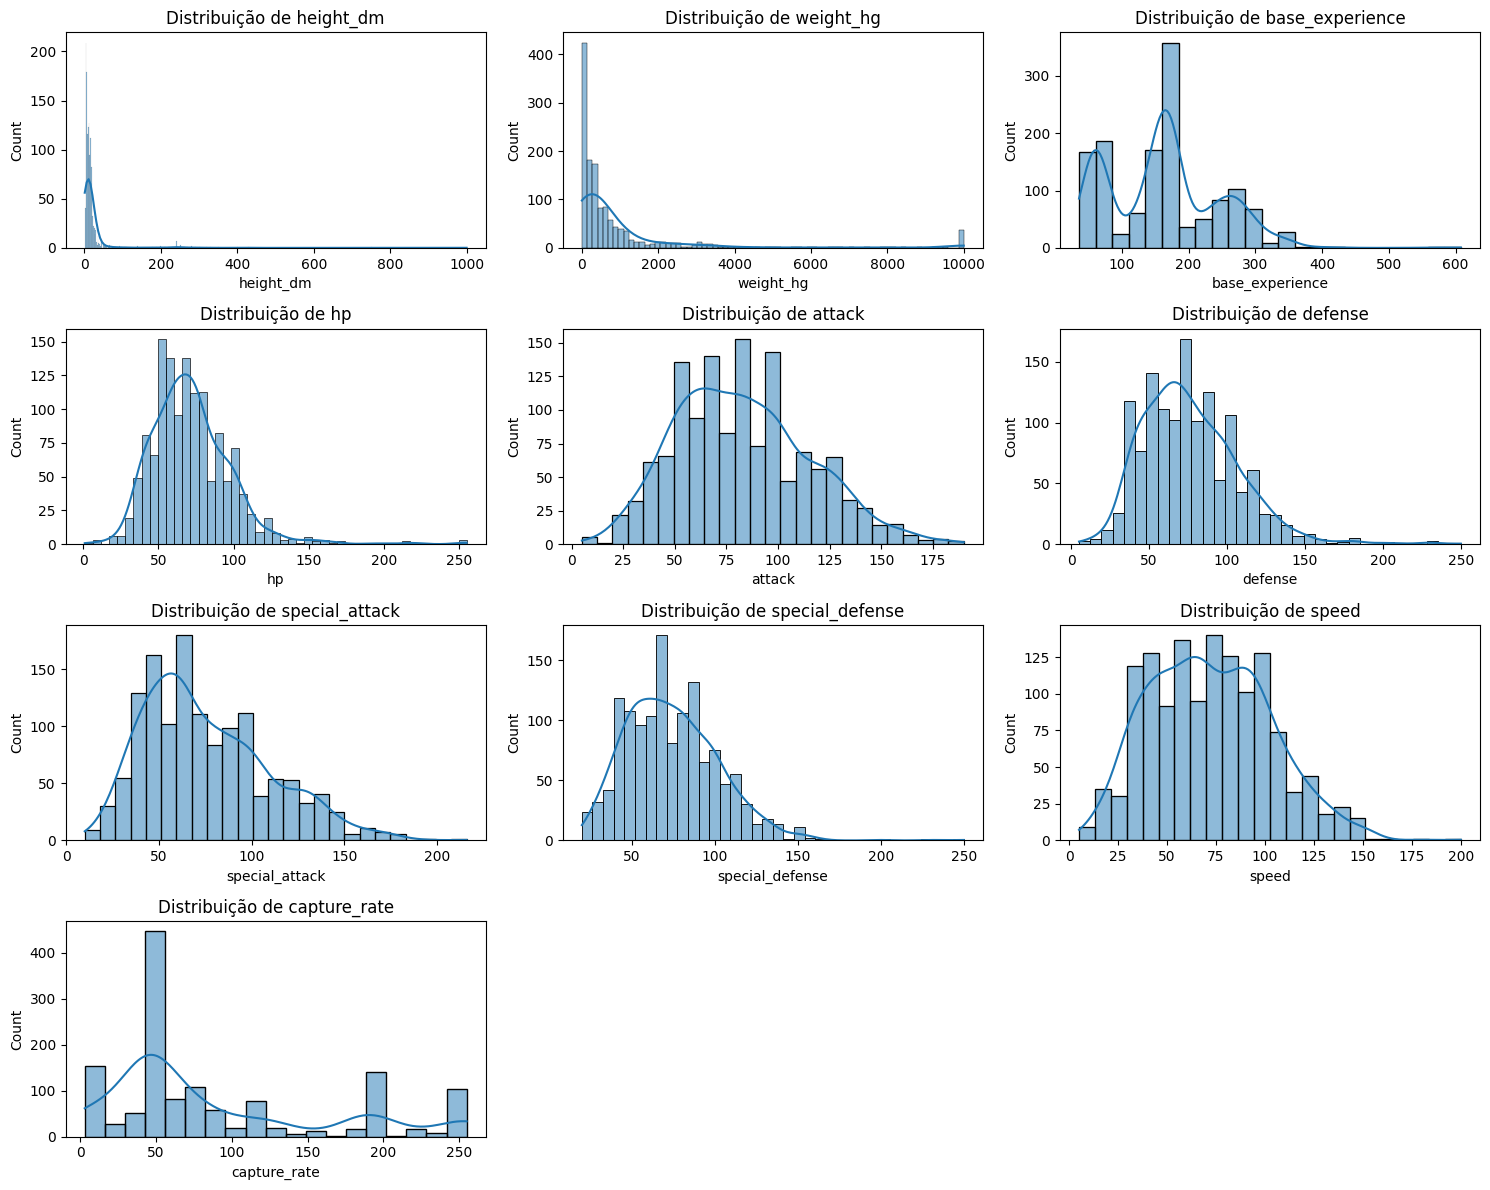

In [25]:
plt.figure(figsize=(num_cols_subplot * 5, num_rows_subplot * 3))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows_subplot, num_cols_subplot, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()

Os histogramas de `height_dm` e `weight_hg` ainda mostram caudas longas por causa das formas especiais identificadas acima. Os boxplots a seguir tornam esses outliers mais visíveis, destacando em separado as formas especiais (`is_special_form`).

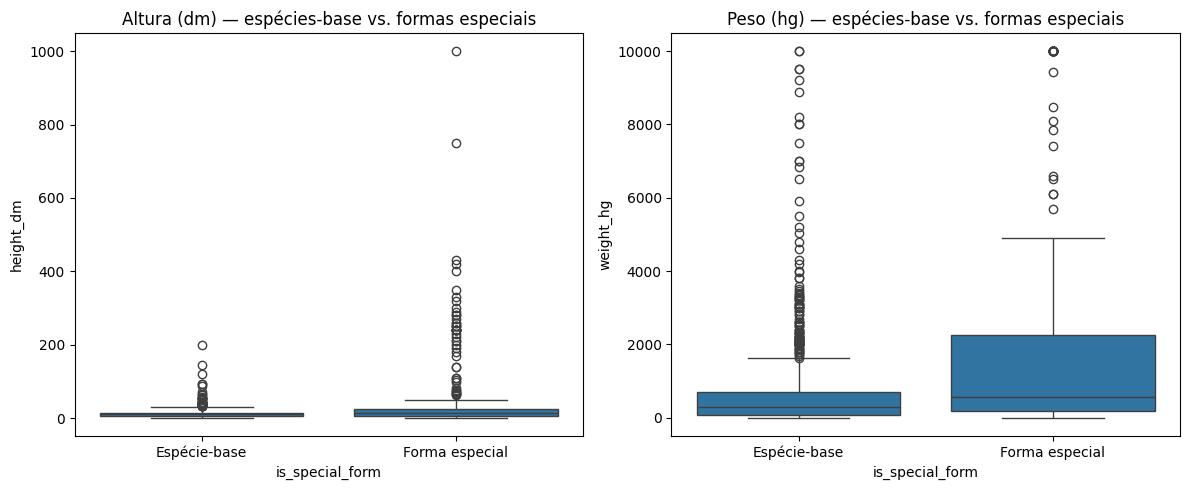

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x='is_special_form', y='height_dm', ax=axes[0])
axes[0].set_title('Altura (dm) — espécies-base vs. formas especiais')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Espécie-base', 'Forma especial'])

sns.boxplot(data=df, x='is_special_form', y='weight_hg', ax=axes[1])
axes[1].set_title('Peso (hg) — espécies-base vs. formas especiais')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Espécie-base', 'Forma especial'])

plt.tight_layout()
plt.show()

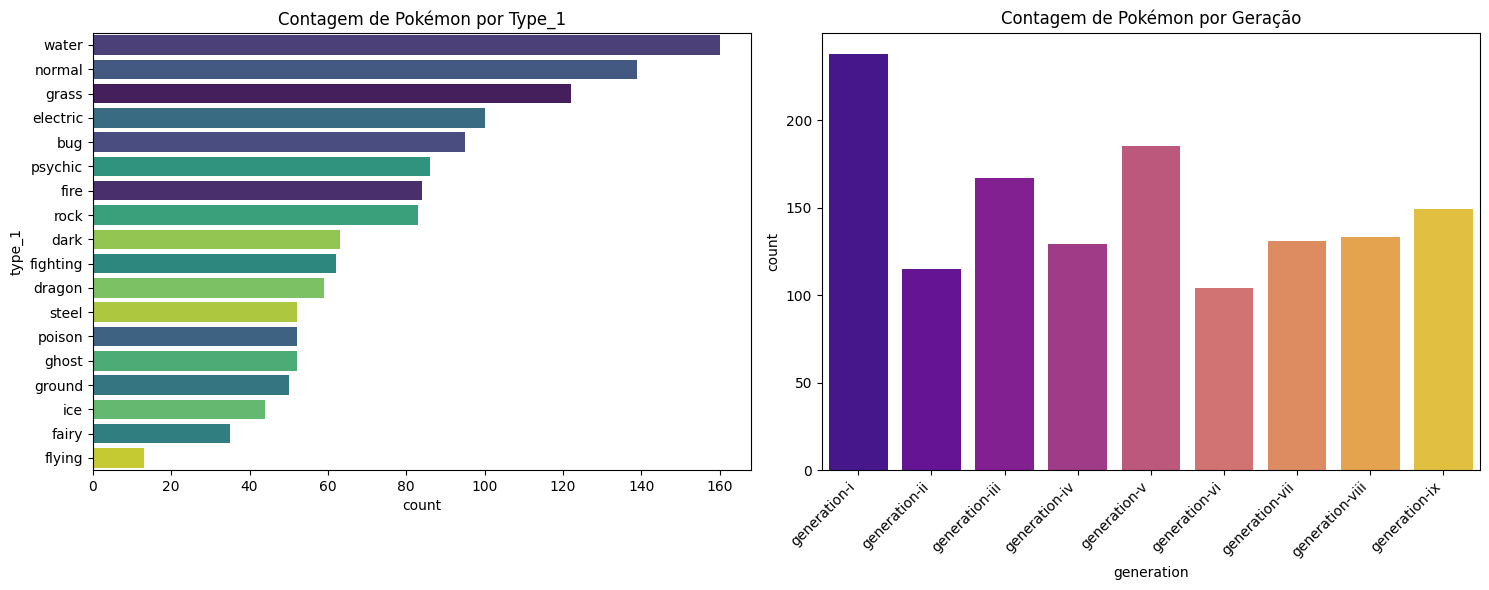

In [27]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
ordem_type1 = df['type_1'].value_counts().index
sns.countplot(y='type_1', data=df, order=ordem_type1, hue='type_1', palette='viridis', legend=False)
plt.title('Contagem de Pokémon por Type_1')

ordem_geracoes = ['generation-i', 'generation-ii', 'generation-iii', 'generation-iv',
                   'generation-v', 'generation-vi', 'generation-vii', 'generation-viii', 'generation-ix']
plt.subplot(1, 2, 2)
sns.countplot(x='generation', data=df, order=ordem_geracoes, hue='generation',
              palette='plasma', legend=False)
plt.title('Contagem de Pokémon por Geração')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()